# 第 3 章 马尔可夫链蒙特卡罗 — 代码实验

对照教材：Shonkwiler & Mendivil《Explorations in Monte Carlo Methods》第 3 章（§3.1–3.8）。

12 个实验，输出图 `out-3-M.png`。随机种子 2026。

In [1]:
# ===== 公共设置 =====
import numpy as np
import math
import matplotlib.pyplot as plt
from pathlib import Path

rng = np.random.default_rng(2026)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch03")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

print("numpy", np.__version__)

numpy 2.4.6


## 实验 1 股市链：收敛 + 谱隙（书 §3.1.2，式 (3.4)(3.7)；习题 1/2）

\(\pi=[37,34,41]/112\)。\(\|p_t-\pi\|\) 的衰减速率由次特征值（谱隙）控制。

解析 π = [0.330357 0.303571 0.366071]，特征向量 π = [0.330357 0.303571 0.366071]
|次特征值| λ2 = 0.1414
相邻比值范围 [0.096, 0.205]，几何平均 = 0.1412 ≈ λ2


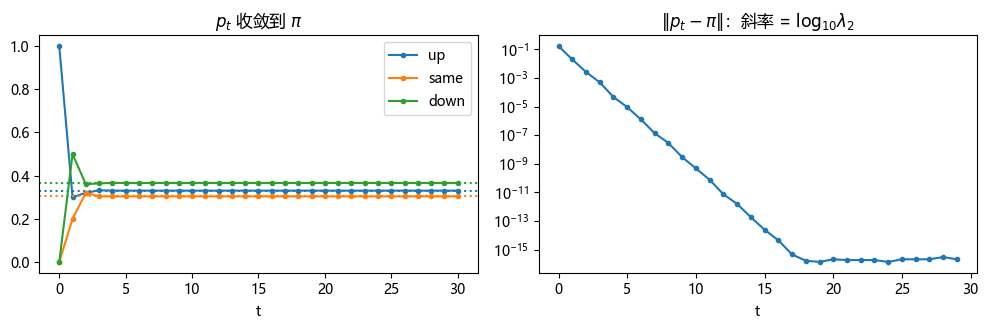

In [2]:
# ===== 书 §3.1.2 股市链 =====
P = np.array([[0.3, 0.2, 0.5],
              [0.4, 0.3, 0.3],
              [0.3, 0.4, 0.3]])      # 行=今日, 列=明日（up/same/down）
pi = np.array([37, 34, 41]) / 112
w, V = np.linalg.eig(P.T)            # 左特征向量
k1 = np.argmin(np.abs(w-1))
pi_eig = np.real(V[:, k1]); pi_eig /= pi_eig.sum()
print(f"解析 π = {pi.round(6)}，特征向量 π = {pi_eig.round(6)}")
lam2 = np.sort(np.abs(w))[-2]
print(f"|次特征值| λ2 = {lam2:.4f}")

p0 = np.array([1.0, 0, 0])
diff = [np.linalg.norm(p0 @ np.linalg.matrix_power(P, t) - pi) for t in range(1, 31)]
ratios = [diff[t+1]/diff[t] for t in range(len(diff)-2)]
# 复特征值使相邻比值振荡；用 log 斜率对比 log(λ2)
# 复特征值对使相邻比值振荡；几何平均 → λ2（习题 2 的正确表述）
ratios = [diff[t+1]/diff[t] for t in range(len(diff)-1)]
good = [r for r, d in zip(ratios, diff[:-1]) if d > 1e-10]
print(f"相邻比值范围 [{min(good):.3f}, {max(good):.3f}]，几何平均 = {np.exp(np.mean(np.log(good))):.4f} ≈ λ2")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
pt = np.array([p0 @ np.linalg.matrix_power(P, t) for t in range(31)])
for j, lab in enumerate(["up", "same", "down"]):
    ax[0].plot(pt[:, j], "-o", ms=3, label=lab)
    ax[0].axhline(pi[j], ls=":", color=f"C{j}")
ax[0].set_xlabel("t"); ax[0].set_title(r"$p_t$ 收敛到 $\pi$"); ax[0].legend()
ax[1].semilogy(diff, "o-", ms=3)
ax[1].set_title(r"$\|p_t-\pi\|$：斜率 = log$_{10}\lambda_2$")
ax[1].set_xlabel("t")
plt.tight_layout(); save(fig, "out-3-1.png"); plt.show()

## 实验 2 沿链采样：累计频率稳定到 π（书 §3.1.1）

用累积矩阵 C 逐行轮盘赌采样，看"实例直方图"如何稳定。

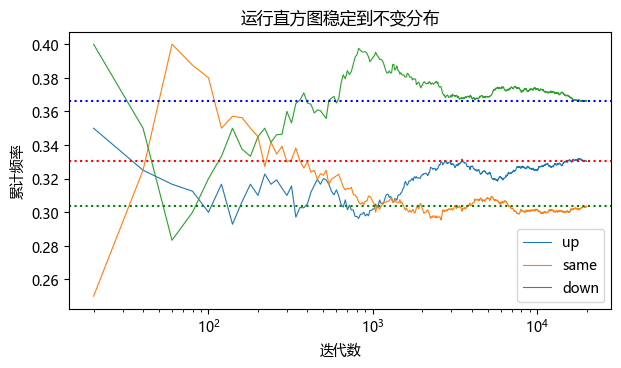

In [3]:
# ===== 书 §3.1.1 链采样 =====
C = np.cumsum(P, axis=1)             # 式 (3.2)
states = ["up", "same", "down"]
x = 0                                 # 从 up 出发
freq = np.zeros(3); run = []
for t in range(1, 20001):
    U = rng.random(); j = int(np.searchsorted(C[x], U, side="right"))
    x = j
    freq[x] += 1
    if t % 20 == 0: run.append(freq/t)
run = np.array(run)
fig, ax = plt.subplots(figsize=(7, 3.6))
for j, lab in enumerate(states):
    ax.plot(np.arange(20, 20001, 20), run[:, j], lw=0.8, label=lab)
for j, c in enumerate("rgb"): ax.axhline(pi[j], ls=":", color=c)
ax.set_xscale("log"); ax.set_xlabel("迭代数"); ax.set_ylabel("累计频率")
ax.set_title("运行直方图稳定到不变分布"); ax.legend()
save(fig, "out-3-2.png"); plt.show()

## 实验 3 Metropolis 骰子（书 §3.2.1，Alg 3.1，Fig 3.4）

目标 f = 骰子和的计数向量；极小邻域（±1，边界自环）。

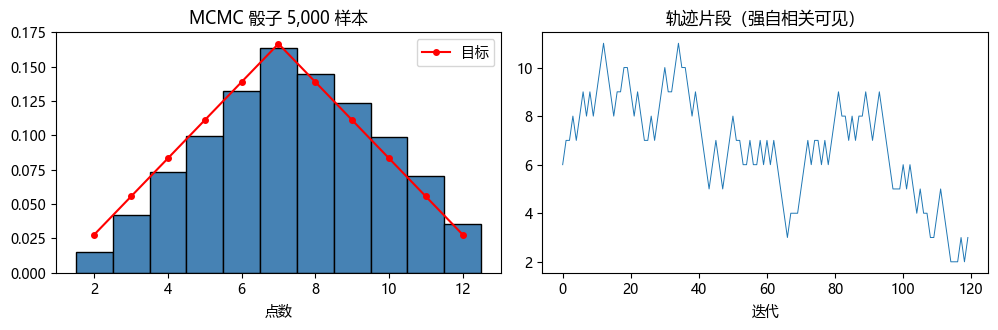

In [4]:
# ===== 书 §3.2.1 Alg 3.1 =====
f = np.array([0,0,1,2,3,4,5,6,5,4,3,2,1], dtype=float)  # 索引=点数 0..12
nTrials = 5000
d = []; x = 5
for i in range(nTrials):
    y = x + (1 if rng.random() < 0.5 else -1)          # 提案
    y = min(max(y, 2), 12)                             # 边界自环
    h = min(1.0, f[y]/f[x])
    if rng.random() < h: x = y
    d.append(x)
d = np.array(d)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ks = np.arange(2, 13)
ax[0].hist(d, bins=np.arange(1.5, 12.6), density=True, color="steelblue", edgecolor="k")
target = f[2:13]/f[2:13].sum()
ax[0].plot(ks, target, "ro-", ms=4, label="目标")
ax[0].set_title("MCMC 骰子 5,000 样本"); ax[0].set_xlabel("点数"); ax[0].legend()
ax[1].plot(d[:120], lw=0.7)
ax[1].set_title("轨迹片段（强自相关可见）"); ax[1].set_xlabel("迭代")
plt.tight_layout(); save(fig, "out-3-3.png"); plt.show()

## 实验 4 提案切换：卡在深谷（书 §3.2.1，Fig 3.5）

目标 f(x)=1/p(x)²（倒数平方）。纯极小邻域过不了 x=7 的深谷；10% 极大邻域切换恢复。

C:\Users\17272\AppData\Local\Temp\ipykernel_108912\3711353332.py:3: RuntimeWarning: divide by zero encountered in divide
  fk = 36.0**2/pk**2                                   # f(2)=f(12)=36²


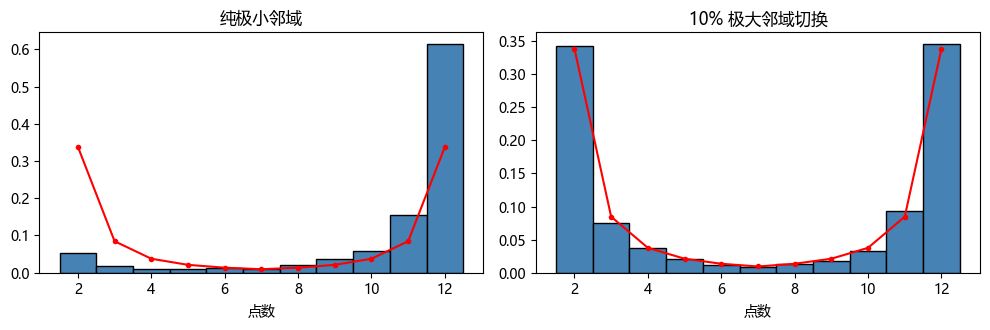

In [5]:
# ===== 书 §3.2.1 Fig 3.5 =====
pk = np.array([0,0,1,2,3,4,5,6,5,4,3,2,1], dtype=float)
fk = 36.0**2/pk**2                                   # f(2)=f(12)=36²
fk[:2] = 0

def run_mc(switch_p, n=5000):
    x = 2; out = []
    for _ in range(n):
        if rng.random() < switch_p:                  # 极大邻域提案
            y = int(rng.integers(2, 13))
        else:                                        # 极小邻域
            y = x + (1 if rng.random() < 0.5 else -1)
            y = min(max(y, 2), 12)
        if fk[y] > 0 and rng.random() < min(1, fk[y]/fk[x]): x = y
        out.append(x)
    return np.array(out)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for k, sp in enumerate([0.0, 0.10]):
    d = run_mc(sp)
    ax[k].hist(d, bins=np.arange(1.5, 12.6), density=True,
               color="steelblue", edgecolor="k")
    ax[k].plot(np.arange(2,13), fk[2:13]/fk[2:13].sum(), "ro-", ms=3)
    ax[k].set_title(f"{'纯极小邻域' if sp==0 else '10% 极大邻域切换'}")
    ax[k].set_xlabel("点数")
plt.tight_layout(); save(fig, "out-3-4.png"); plt.show()

## 实验 5 连续 Metropolis：步长效应（书 §3.2.1，Fig 3.6；习题 4）

目标 f=0.5x²e^{−x}（\(\Omega=[0,\infty)\)）。提案 U(x−δ,x+δ)，负提案原地不动。

δ=1.0: 移动率(≈接受率) = 0.866


δ=8.0: 移动率(≈接受率) = 0.300


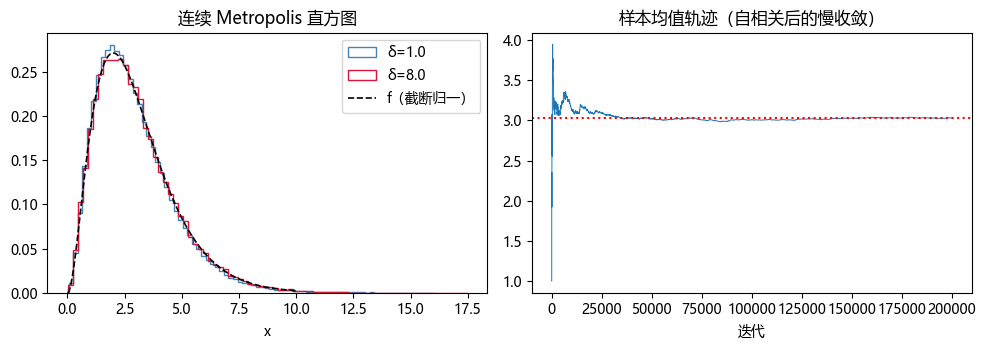

In [6]:
# ===== 书 §3.2.1 连续链 =====
def fcon(x): return 0.5*x*x*np.exp(-x)

def run_cont(delta, n=200_000, x0=1.0):
    x = x0; out = np.empty(n)
    for i in range(n):
        y = x - delta + 2*delta*rng.random()
        if y < 0: y = x                              # 边界自环
        if rng.random() < min(1, fcon(y)/fcon(x)): x = y
        out[i] = x
    return out

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
t = np.linspace(0, 10, 400)
pdf = fcon(t)/ (2 - 5*np.exp(-10) - 5*10*np.exp(-10)*0)  # 近似归一（尾部截断小）
pdf = fcon(t)
for delta, c in [(1.0, "steelblue"), (8.0, "crimson")]:
    s = run_cont(delta)
    ax[0].hist(s, bins=80, density=True, histtype="step", lw=1.5, color=c,
               label=f"δ={delta}")
    ar = np.mean(np.diff(s) != 0)
    print(f"δ={delta}: 移动率(≈接受率) = {ar:.3f}")
ax[0].plot(t, pdf/np.trapezoid(pdf, t), "k--", lw=1.2, label="f（截断归一）")
ax[0].set_title("连续 Metropolis 直方图"); ax[0].set_xlabel("x"); ax[0].legend()
run = np.cumsum(run_cont(1.0, 200_000))/np.arange(1, 200_001)
ax[1].plot(run, lw=0.7); ax[1].axhline(run[-1], color="r", ls=":")
ax[1].set_title("样本均值轨迹（自相关后的慢收敛）"); ax[1].set_xlabel("迭代")
plt.tight_layout(); save(fig, "out-3-5.png"); plt.show()

## 实验 6 细致平衡与质量守恒的数值验证（书 §3.2.2，式 (3.11)(3.12)）

对骰子 Metropolis 链显式构造转移矩阵 p_xy = g_x(y)h(x,y)，验证 π(x)p_xy = π(y)p_yx 与流入=流出。

细致平衡最大残差 max|π(x)p_xy − π(y)p_yx| = 8.67e-19
质量守恒最大残差（式 3.11）            = 1.73e-18


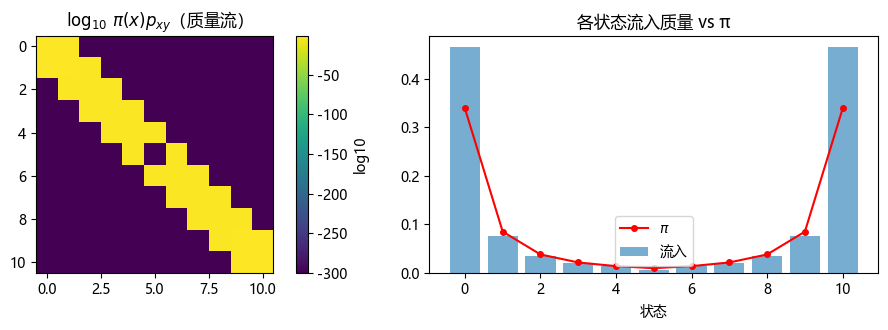

In [7]:
# ===== 书 §3.2.2 细致平衡 =====
nS = 11; idx = {v: i for i, v in enumerate(range(2, 13))}
Pm = np.zeros((nS, nS))
for i in range(nS):
    for j in (i-1, i+1):                        # ±1 提案，各 1/2
        if 0 <= j < nS:
            Pm[i, j] = 0.5 * min(1, fk[j+2]/fk[i+2])
    Pm[i, i] = 1.0 - Pm[i].sum()                # 拒绝或出界提案 → 原地（自环）
pi_m = fk[2:13]/fk[2:13].sum()
lhs = pi_m[:, None]*Pm; rhs = pi_m[None, :]*Pm.T
db = np.abs(lhs - rhs).max()
flow_err = np.abs(pi_m @ Pm - pi_m).max()      # πP = π
print(f"细致平衡最大残差 max|π(x)p_xy − π(y)p_yx| = {db:.2e}")
print(f"质量守恒最大残差（式 3.11）            = {flow_err:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
im = ax[0].imshow(np.log10(lhs + 1e-300), cmap="viridis")
ax[0].set_title(r"$\log_{10}\,\pi(x)p_{xy}$（质量流）"); fig.colorbar(im, ax=ax[0], label="log10")
ax[1].bar(range(nS), Pm.sum(axis=0)*pi_m, alpha=0.6, label="流入")
ax[1].plot(range(nS), pi_m, "ro-", ms=4, label=r"$\pi$")
ax[1].set_title("各状态流入质量 vs π"); ax[1].legend(); ax[1].set_xlabel("状态")
plt.tight_layout(); save(fig, "out-3-6.png"); plt.show()

## 实验 7 遍历定理（书 §3.3，定理 3.1）

对股市链取 r(x)=x（0,1,2），时间平均应收敛到 E_π[r]=\(\pi\cdot[0,1,2]\)。

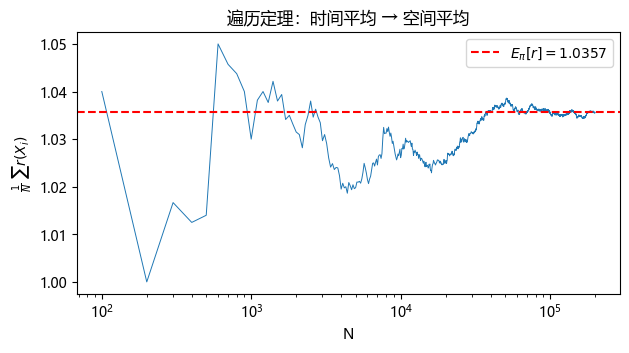

In [8]:
# ===== 书 §3.3 遍历定理 =====
C3 = np.cumsum(P, axis=1)
x = 0; s = 0.0; run = []
for t in range(1, 200_001):
    x = int(np.searchsorted(C3[x], rng.random(), side="right"))
    s += x
    if t % 100 == 0: run.append(s/t)
Ep = pi @ np.array([0.0, 1.0, 2.0])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(np.arange(100, 200_001, 100), run, lw=0.7)
ax.axhline(Ep, color="r", ls="--", label=fr"$E_{{\pi}}[r]={Ep:.4f}$")
ax.set_xscale("log"); ax.set_xlabel("N"); ax.set_ylabel(r"$\frac{1}{N}\ \sum r(X_i)$")
ax.set_title("遍历定理：时间平均 → 空间平均"); ax.legend()
save(fig, "out-3-7.png"); plt.show()

## 实验 8 Ising 2×2 精确枚举（书 §3.5 表）

16 个微观态 × 两个温度；Z 应为 16.004（T=100）与 121.22（T=1）。

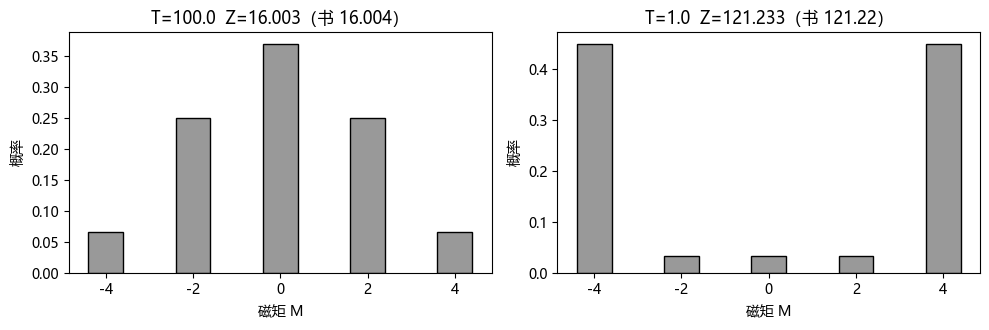

低温下全同向态概率: [0.45]


In [9]:
# ===== 书 §3.5 2×2 枚举 =====
states4 = np.array([[s0, s1, s2, s3] for s0 in (1,-1) for s1 in (1,-1)
                    for s2 in (1,-1) for s3 in (1,-1)])
def E2x2(s):     # 自由边界：两行横对 + 两列竖对，各对 −xixj
    return -(s[0]*s[1] + s[2]*s[3] + s[0]*s[2] + s[1]*s[3])
E = np.array([E2x2(s) for s in states4])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for k, (T, Zbook) in enumerate([(100.0, 16.004), (1.0, 121.22)]):
    b = 1.0/T
    wts = np.exp(-b*E); Z = wts.sum(); pr = wts/Z
    Mm = states4.sum(axis=1)
    agg = {m: pr[Mm == m].sum() for m in sorted(set(Mm))}
    ax[k].bar(list(agg), list(agg.values()), color="0.6", edgecolor="k")
    ax[k].set_title(f"T={T}  Z={Z:.3f}（书 {Zbook}）")
    ax[k].set_xlabel("磁矩 M"); ax[k].set_ylabel("概率")
plt.tight_layout(); save(fig, "out-3-8.png"); plt.show()
print("低温下全同向态概率:", np.round(np.exp(-1*E[states4.sum(axis=1)==4]/1.0)/
      np.exp(-1*E).sum(), 3))

## 实验 9 Ising 16×16 相变扫描（书 §3.5，Alg 3.2 思路，Fig 3.7/3.8）

Metropolis 单自旋翻转 + 周期边界。临界温度 ≈ 2.27（k_B=1, J=1）。

T=1.0:  |<M>|/spin = 1.000
T=1.5:  |<M>|/spin = 0.987


T=2.0:  |<M>|/spin = 0.910


T=2.27:  |<M>|/spin = 0.208
T=2.7:  |<M>|/spin = 0.196


T=3.5:  |<M>|/spin = 0.024
T=5.0:  |<M>|/spin = 0.002


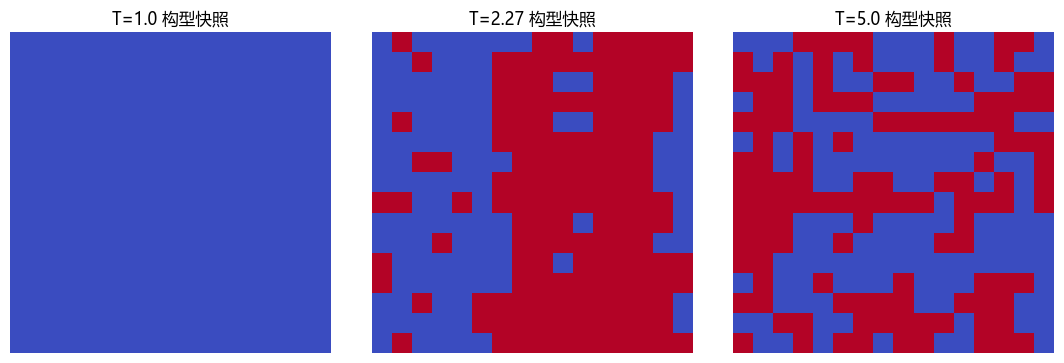

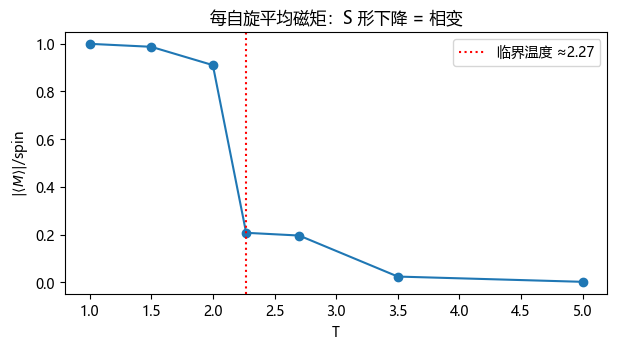

In [10]:
# ===== 书 §3.5 Ising 扫描 =====
L = 16
def ising_run(T, burnin=20_000, nTrials=20_000, snap=False):
    b = 1.0/T
    s = rng.choice([-1, 1], size=(L, L))
    E = 0
    for dx in (1, -1): E -= int((s*np.roll(s, dx, axis=0)).sum())
    for dy in (1, -1): E -= int((s*np.roll(s, dy, axis=1)).sum())
    E //= 2                                     # 每对只计一次
    Msum = 0
    for t in range(burnin + nTrials):
        i, j = rng.integers(L), rng.integers(L)
        nb = s[(i+1)%L, j] + s[(i-1)%L, j] + s[i, (j+1)%L] + s[i, (j-1)%L]
        dE = 2*s[i, j]*nb
        if dE <= 0 or rng.random() < np.exp(-b*dE):
            s[i, j] = -s[i, j]; E += dE
        if t >= burnin: Msum += s.sum()
    return s, Msum/nTrials/L**2

Ts = [1.0, 1.5, 2.0, 2.27, 2.7, 3.5, 5.0]
snaps = {}; mags = []
for T in Ts:
    s, m = ising_run(T, snap=True)
    mags.append(abs(m))
    if T in (1.0, 2.27, 5.0): snaps[T] = s.copy()
    print(f"T={T}:  |<M>|/spin = {abs(m):.3f}")

fig, ax = plt.subplots(1, 3, figsize=(11, 3.6))
for a, (T, s) in zip(ax, snaps.items()):
    a.imshow(s, cmap="coolwarm"); a.set_title(f"T={T} 构型快照"); a.axis("off")
plt.tight_layout(); save(fig, "out-3-9a.png"); plt.show()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(Ts, mags, "o-")
ax.axvline(2.27, ls=":", color="r", label="临界温度 ≈2.27")
ax.set_xlabel("T"); ax.set_ylabel(r"$|\langle M\rangle|$/spin")
ax.set_title("每自旋平均磁矩：S 形下降 = 相变"); ax.legend()
save(fig, "out-3-9.png"); plt.show()

## 实验 10 Metropolis–Hastings：非对称提案（书 §3.6，Alg 3.3，Fig 3.9）

上步提议率 2/3、下步 1/3。纯 Metropolis 系统性右偏；MH 修正恢复。

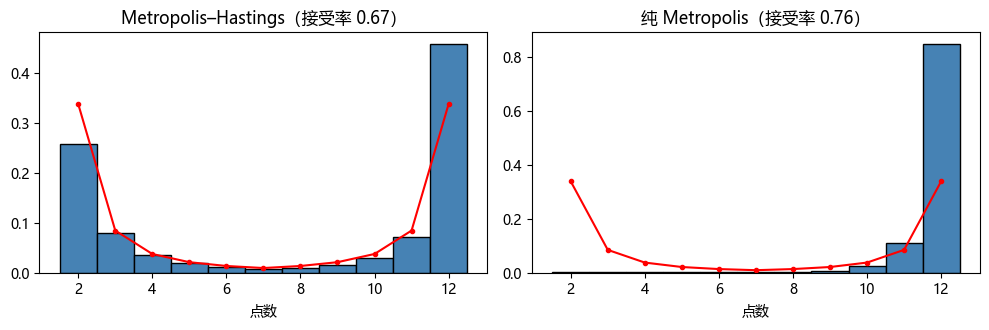

In [11]:
# ===== 书 §3.6 Alg 3.3 =====
def g_asym(x, y):
    if x == 2 or x == 12: return 0.5
    return 2/3 if y == x+1 else 1/3

def run_mh(hastings, n=20_000):
    x = 5; out = []; acc = 0
    for _ in range(n):
        y = x+1 if rng.random() < 2/3 else x-1
        y = min(max(y, 2), 12)
        if hastings:
            h = min(1, fk[y]*g_asym(y, x)/(fk[x]*g_asym(x, y)))
        else:
            h = min(1, fk[y]/fk[x])
        if rng.random() < h: x = y; acc += 1
        out.append(x)
    return np.array(out), acc/n

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for k, (flag, lab) in enumerate([(True, "Metropolis–Hastings"), (False, "纯 Metropolis")]):
    d, ar = run_mh(flag)
    ax[k].hist(d, bins=np.arange(1.5, 12.6), density=True,
               color="steelblue", edgecolor="k")
    ax[k].plot(np.arange(2, 13), fk[2:13]/fk[2:13].sum(), "ro-", ms=3)
    ax[k].set_title(f"{lab}（接受率 {ar:.2f}）"); ax[k].set_xlabel("点数")
plt.tight_layout(); save(fig, "out-3-10.png"); plt.show()

## 实验 11 Coupling from the Past（书 §3.8.2，Fig 3.11；习题 7）

同一随机数驱动**所有**状态从 t=−k 前进；坍缩即得 π 的**精确**样本。

CFTP 频率: [0.3275 0.3087 0.3638]  精确 π: [0.3304 0.3036 0.3661]


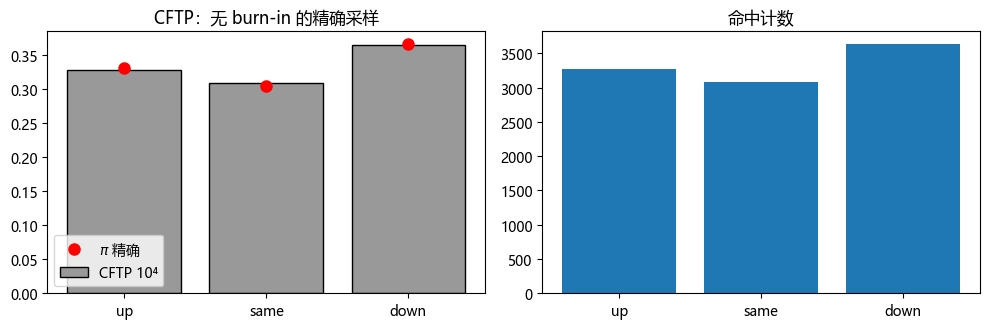

In [12]:
# ===== 书 §3.8.2 CFTP =====
def cftp_one():
    rs = list(rng.random(16))          # 预选随机数（存着复用）
    W = 16
    while True:
        states = [0, 1, 2]             # U, same, down
        for r in rs[:W][::-1]:         # 从 t=-W 走到 -1（旧数在前）
            states = [int(np.searchsorted(C[x], r, side="right")) for x in states]
        if len(set(states)) == 1:
            return states[0]
        W *= 2                         # 不耦合：往回加新数（旧的保留）
        if W > 4096: raise RuntimeError("未耦合")

Nc = 10_000
samp = np.array([cftp_one() for _ in range(Nc)])
freq = np.bincount(samp, minlength=3)/Nc
print("CFTP 频率:", freq.round(4), " 精确 π:", pi.round(4))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(["up", "same", "down"], freq, color="0.6", edgecolor="k", label="CFTP 10⁴")
ax[0].plot(range(3), pi, "ro", ms=8, label=r"$\pi$ 精确")
ax[0].set_title("CFTP：无 burn-in 的精确采样"); ax[0].legend()
ax[1].bar(range(3), np.bincount(samp, minlength=3))
ax[1].set_xticks(range(3), ["up", "same", "down"]); ax[1].set_title("命中计数")
plt.tight_layout(); save(fig, "out-3-11.png"); plt.show()

## 实验 12 图匹配计数（书 §3.7，Alg 3.4，Table 3.1）

书 Fig 3.10 的 14 边二部图。MCMC 均匀采样匹配 → 频次比链式估计 #M_k；2¹⁴=16384 枚举给精确值对照。

精确 #M_k = {0: 1, 1: 14, 2: 71, 3: 160, 4: 157, 5: 56, 6: 4}


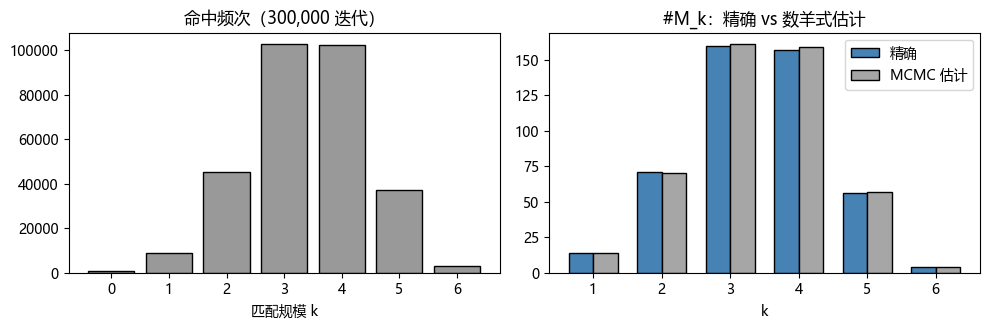

MCMC 估计: {1: np.float64(13.9), 2: np.float64(70.0), 3: np.float64(161.2), 4: np.float64(159.5), 5: np.float64(56.8), 6: np.float64(4.3)}


In [13]:
# ===== 书 §3.7 Alg 3.4 =====
edges = [(0,6),(0,8),(0,10),(1,7),(1,10),(2,9),(2,11),(3,6),(3,8),
         (3,11),(4,10),(4,11),(5,7),(5,9)]
NE = len(edges)

def exact_counts():                  # 枚举 2^14 个子集
    cnt = {}
    for mask in range(1 << NE):
        used = 0; k = 0; ok = True
        for i in range(NE):
            if mask >> i & 1:
                u, v = edges[i]
                if used & (1 << u) or used & (1 << v): ok = False; break
                used |= (1 << u) | (1 << v); k += 1
        if ok: cnt[k] = cnt.get(k, 0) + 1
    return cnt
ex = exact_counts()
print("精确 #M_k =", {k: ex.get(k, 0) for k in range(7)})

hits = np.zeros(7)
mset = set(); ksize = 0
for t in range(300_000):
    i = int(rng.integers(NE))
    u, v = edges[i]
    if i in mset:
        mset.discard(i); ksize -= 1
    else:
        lu = [j for j in mset if u in edges[j]]
        lv = [j for j in mset if v in edges[j]]
        if not lu and not lv: mset.add(i); ksize += 1
        elif lu and not lv:   mset.discard(lu[0]); mset.add(i)
        elif lv and not lu:   mset.discard(lv[0]); mset.add(i)
    hits[ksize] += 1
est = {k: hits[k]/hits[k-1]*ex.get(k-1, 0) for k in range(1, 7) if hits[k-1] > 0}

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ks = range(7)
ax[0].bar(list(ks), [hits[k] for k in ks], color="0.6", edgecolor="k")
ax[0].set_title(f"命中频次（300,000 迭代）"); ax[0].set_xlabel("匹配规模 k")
ax[1].bar([k-0.18 for k in est], [ex.get(k, 0) for k in est], 0.36,
          label="精确", color="steelblue", edgecolor="k")
ax[1].bar([k+0.18 for k in est], [est[k] for k in est], 0.36,
          label="MCMC 估计", color="0.65", edgecolor="k")
ax[1].set_title("#M_k：精确 vs 数羊式估计"); ax[1].set_xlabel("k"); ax[1].legend()
plt.tight_layout(); save(fig, "out-3-12.png"); plt.show()
print("MCMC 估计:", {k: round(v, 1) for k, v in est.items()})